# Task 2 — Data Preprocessing, Feature Engineering & ML Pipeline

## Objective
Prepare the IBM HR Analytics Employee Attrition data for Task 3: validate and clean rows, inspect types and quality, engineer two explainable features, compare encoders/scalers, diagnose outliers, create a leakage-safe stratified split, and fit/save a reusable Scikit-learn preprocessor. **No predictive model is trained here.** `Attrition` stays separate from all feature transformations.

**Dataset source:** IBM HR Analytics Employee Attrition & Performance, distributed on [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) and mirrored as the original CSV in this project. This is a fictional learning dataset (1,470 employees, 35 columns).

## Imports and portable project paths
Run cells from this notebook or the project root. Paths are discovered relative to the repository; no personal absolute paths are embedded in reusable code.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Open this notebook inside the AI-ML-Internship project.')
sys.path.insert(0, str(PROJECT_ROOT))
from src.hr_validation import load_employee_data, profile_data, clean_hr_data, TARGET
from src.feature_engineering import HRFeatureEngineer
from src.preprocessing_pipeline import identify_feature_types, load_preprocessor
from src.hr_preprocessing import (split_employee_data, compare_scalers, iqr_outlier_table, run_preprocessing)
RAW_PATH = PROJECT_ROOT / 'data' / 'raw' / 'employee_attrition.csv'
raw = load_employee_data(RAW_PATH)
print('Raw dataset shape:', raw.shape)
display(raw.head(10))
print('Dtypes:'); display(raw.dtypes.to_frame('dtype'))

Raw dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


Dtypes:


,dtype
Age,int64
Attrition,str
BusinessTravel,str
DailyRate,int64
Department,str
DistanceFromHome,int64
Education,int64
EducationField,str
EmployeeCount,int64
EmployeeNumber,int64


## Business target and data-quality inspection
Attrition is the binary outcome (`Yes`/`No`) for a later prediction task. Count nulls and duplicate rows before cleaning; do not scale or encode the target as a feature.

In [2]:
raw_profile = profile_data(raw)
print('Missing cells:', raw_profile['missing_cells'])
print('Missing values by column:'); display(pd.Series(raw_profile['missing_by_column']).to_frame('missing'))
print('Exact duplicate rows:', raw_profile['duplicate_rows'])
print('Target counts:', raw_profile['target_counts'])

Missing cells: 0
Missing values by column:


,missing
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


Exact duplicate rows: 0
Target counts: {'No': 1233, 'Yes': 237}


## Cleaning and validation
The cleaning function trims string values, canonicalizes target labels, corrects numeric strings where every non-empty value parses, drops exact duplicates, and rejects invalid target values. The source dataset has no missing feature values; where future compatible files do have them, median/mode imputers are fit only on `X_train` inside the pipeline. Rows with missing target cannot support supervised Task 3 and are removed.

In [3]:
clean, cleaning_log = clean_hr_data(raw)
print('Cleaning log:', cleaning_log)
print('Clean shape:', clean.shape)
print('Remaining missing cells:', int(clean.isna().sum().sum()))
display(clean.head())

Cleaning log: {'rows_before': 1470, 'columns_before': 35, 'missing_cells_before': 0, 'duplicate_rows_before': 0, 'duplicate_rows_removed': 0, 'rows_with_missing_target_removed': 0, 'rows_after': 1470, 'missing_cells_after': 0, 'categorical_values_trimmed': True, 'numeric_string_columns_converted': ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'], 'imputation': 'No full-data imputation; numerical medians and categorical modes are learned from training rows inside the pipeline.', 'target_handling': 'Attrition retained separately as Yes/No and is nev

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Train/test split and feature types
Make the split before fitting any imputer, outlier fence, encoder, or scaler. A fixed random state plus stratification preserves class proportions. ID fields and constant columns are excluded based on training schema; `Attrition` is not passed to the preprocessing pipeline.

In [4]:
X_train, X_test, y_train, y_test = split_employee_data(clean)
print('Train/test rows:', len(X_train), len(X_test))
print('Train class shares:'); display(y_train.value_counts(normalize=True).rename('share'))
print('Test class shares:'); display(y_test.value_counts(normalize=True).rename('share'))
engineered_train = HRFeatureEngineer().fit_transform(X_train)
feature_types = identify_feature_types(engineered_train)
print('Numerical features:', len(feature_types['numeric']), feature_types['numeric'])
print('Categorical features:', len(feature_types['categorical']), feature_types['categorical'])
print('Excluded identifier/constant columns:', feature_types['dropped'])
assert TARGET not in X_train.columns

Train/test rows: 1176 294
Train class shares:


Attrition
No     0.838435
Yes    0.161565
Name: share, dtype: float64

Test class shares:


Attrition
No     0.840136
Yes    0.159864
Name: share, dtype: float64

Numerical features: 23 ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical features: 9 ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'CareerStage', 'CompanyTenureBand']
Excluded identifier/constant columns: ['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']


## Feature engineering
Two deterministic, domain-readable bins are created from available fields: `CareerStage` from age, and `CompanyTenureBand` from years at the company. Since these features are row-wise transformations, the same rules can be applied to unseen records. They are built inside the persisted pipeline as well as included in the cleaned CSV for inspection.

In [5]:
display(engineered_train[['Age', 'CareerStage', 'YearsAtCompany', 'CompanyTenureBand']].head(10))
print('Derived features:', ['CareerStage', 'CompanyTenureBand'])

,Age,CareerStage,YearsAtCompany,CompanyTenureBand
1194,47,Later (45+),3,2-5 years
128,22,Early (<30),2,2-5 years
810,46,Later (45+),12,11+ years
478,25,Early (<30),7,6-10 years
491,43,Mid (30-44),8,6-10 years
323,28,Early (<30),3,2-5 years
258,51,Later (45+),1,0-1 years
812,43,Mid (30-44),8,6-10 years
1132,40,Mid (30-44),5,2-5 years
996,27,Early (<30),6,6-10 years


Derived features: ['CareerStage', 'CompanyTenureBand']


## Label Encoding versus One-Hot Encoding
Compare both encodings on the **same nominal feature** (`BusinessTravel`) using training rows only. Integer label codes can imply a false order, so the reusable pipeline uses One-Hot Encoding with `handle_unknown='ignore'` for unseen category values. LabelEncoder is demonstrated only; `Attrition` remains outside the feature transformer.

In [6]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
travel_train = X_train['BusinessTravel'].fillna(X_train['BusinessTravel'].mode().iloc[0]).astype(str)
label_encoder = LabelEncoder().fit(travel_train)
label_codes = label_encoder.transform(travel_train)
onehot_demo = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(travel_train.to_frame())
print('Label mapping:', dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))
print('One-hot columns:', onehot_demo.get_feature_names_out(['BusinessTravel']).tolist())
comparison = pd.DataFrame({'BusinessTravel': travel_train.head(8).to_list(), 'LabelEncoded': label_codes[:8].tolist()})
display(comparison)
display(pd.DataFrame(onehot_demo.transform(travel_train.head(8).to_frame()).astype(int), columns=onehot_demo.get_feature_names_out(['BusinessTravel'])))

Label mapping: {'Non-Travel': np.int64(0), 'Travel_Frequently': np.int64(1), 'Travel_Rarely': np.int64(2)}
One-hot columns: ['BusinessTravel_Non-Travel', 'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely']


,BusinessTravel,LabelEncoded
0,Travel_Rarely,2
1,Travel_Rarely,2
2,Travel_Rarely,2
3,Travel_Rarely,2
4,Travel_Frequently,1
5,Travel_Rarely,2
6,Travel_Rarely,2
7,Travel_Frequently,1


,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,1,0
5,0,0,1
6,0,0,1
7,0,1,0


## Scaling comparison using training data only
StandardScaler centers features and scales to unit variance; MinMaxScaler maps training values to [0, 1]. Scaling matters for distance- and gradient-based algorithms such as SVMs and Logistic Regression because feature units otherwise affect optimization and distances. Tree-based models are generally less sensitive. The saved pipeline uses StandardScaler; choose model-specific preprocessing later in Task 3.

In [7]:
scale_results = compare_scalers(X_train['MonthlyIncome'])
print({name: {k: v for k, v in result.items() if k != 'values'} for name, result in scale_results.items()})
display(pd.DataFrame({'MonthlyIncome': X_train['MonthlyIncome'].head(8).to_numpy(), 'StandardScaler': scale_results['StandardScaler']['values'][:8], 'MinMaxScaler': scale_results['MinMaxScaler']['values'][:8]}))

{'StandardScaler': {'mean': -7.930164461608261e-17, 'std': 1.0, 'min': -1.1898762678287278, 'max': 2.886855983560853, 'fitted_rows': 1176}, 'MinMaxScaler': {'mean': 0.29187010440117833, 'std': 0.24529450018679633, 'min': 0.0, 'max': 1.0, 'fitted_rows': 1176}}


,MonthlyIncome,StandardScaler,MinMaxScaler
0,15972,2.026752,0.789021
1,2523,-0.864408,0.079835
2,17465,2.347706,0.867749
3,2096,-0.956202,0.057319
4,5679,-0.185956,0.246256
5,3464,-0.662120,0.129456
6,2723,-0.821414,0.090382
7,10820,0.919216,0.517349


## Outlier inspection and handling
Use box plots and 1.5×IQR fences to flag unusual numeric observations. These flags are not proof of bad records: the fictional HR sample has plausible compensation and tenure extremes, so rows are retained in the cleaned CSV. For the reusable transform, continuous numeric columns are capped at fences learned from the training partition only; low-cardinality rating/code fields are left unchanged.

In [8]:
outlier_table = iqr_outlier_table(clean)
display(outlier_table.head(15))
print('Full-data IQR counts are diagnostic only. Pipeline clipping bounds are fitted using training data only.')

,feature,q1,q3,lower_fence,upper_fence,outlier_count,outlier_pct
0,TrainingTimesLastYear,2.00,3.00,0.500,4.500,238,16.190476
1,PerformanceRating,3.00,3.00,3.000,3.000,226,15.374150
2,MonthlyIncome,2911.00,8379.00,-5291.000,16581.000,114,7.755102
3,YearsSinceLastPromotion,0.00,3.00,-4.500,7.500,107,7.278912
4,YearsAtCompany,3.00,9.00,-6.000,18.000,104,7.074830
5,StockOptionLevel,0.00,1.00,-1.500,2.500,85,5.782313
6,TotalWorkingYears,6.00,15.00,-7.500,28.500,63,4.285714
7,NumCompaniesWorked,1.00,4.00,-3.500,8.500,52,3.537415
8,YearsInCurrentRole,2.00,7.00,-5.500,14.500,21,1.428571
9,YearsWithCurrManager,2.00,7.00,-5.500,14.500,14,0.952381


Full-data IQR counts are diagnostic only. Pipeline clipping bounds are fitted using training data only.


## Build and persist the reusable preprocessing pipeline
The orchestration saves the cleaned CSV, reproducible split manifest, five actual preprocessing charts, fitted Joblib pipeline, and JSON results. The split is 80/20 with `random_state=42` and `stratify=Attrition`. Numeric imputation, IQR fences, and StandardScaler are fitted on training rows only; categorical mode imputation and OneHotEncoder are also fit on training rows only.

In [9]:
results = run_preprocessing(RAW_PATH)
print('Pipeline configuration:'); display(results['pipeline'])
print('Split summary:', {k: results['split'][k] for k in ['random_state','test_size','train_rows','test_rows','train_target_counts','test_target_counts','transformed_train_shape','transformed_test_shape']})
print('Saved pipeline:', PROJECT_ROOT / 'models' / 'preprocessor.pkl')

{
  "raw_shape": [
    1470,
    35
  ],
  "clean_shape": [
    1470,
    35
  ],
  "missing": 0,
  "duplicates_removed": 0,
  "train_rows": 1176,
  "test_rows": 294,
  "transformed_train_shape": [
    1176,
    58
  ],
  "model": "C:\\Users\\shubh\\Documents\\Codex\\2026-10-14\\autonomous-project-build-ai-ml-internship\\AI-ML-Internship-Task-2\\models\\preprocessor.pkl",
  "charts": [
    "images\\attrition_target_distribution.png",
    "images\\monthly_income_outliers.png",
    "images\\iqr_outlier_counts.png",
    "images\\scaler_comparison_monthly_income.png",
    "images\\attrition_by_tenure_band.png"
  ]
}
Pipeline configuration:


{'numeric_features': ['Age',
  'DailyRate',
  'DistanceFromHome',
  'Education',
  'EnvironmentSatisfaction',
  'HourlyRate',
  'JobInvolvement',
  'JobLevel',
  'JobSatisfaction',
  'MonthlyIncome',
  'MonthlyRate',
  'NumCompaniesWorked',
  'PercentSalaryHike',
  'PerformanceRating',
  'RelationshipSatisfaction',
  'StockOptionLevel',
  'TotalWorkingYears',
  'TrainingTimesLastYear',
  'WorkLifeBalance',
  'YearsAtCompany',
  'YearsInCurrentRole',
  'YearsSinceLastPromotion',
  'YearsWithCurrManager'],
 'categorical_features': ['BusinessTravel',
  'Department',
  'EducationField',
  'Gender',
  'JobRole',
  'MaritalStatus',
  'OverTime',
  'CareerStage',
  'CompanyTenureBand'],
 'dropped_id_and_constant_features': ['EmployeeNumber',
  'EmployeeCount',
  'Over18',
  'StandardHours'],
 'numeric_steps': ['median imputation',
  'train-fitted IQR capping for continuous columns',
  'StandardScaler'],
 'categorical_steps': ['most-frequent imputation',
  "OneHotEncoder(handle_unknown='ignore

Split summary: {'random_state': 42, 'test_size': 0.2, 'train_rows': 1176, 'test_rows': 294, 'train_target_counts': {'No': 986, 'Yes': 190}, 'test_target_counts': {'No': 247, 'Yes': 47}, 'transformed_train_shape': [1176, 58], 'transformed_test_shape': [294, 58]}
Saved pipeline: C:\Users\shubh\Documents\Codex\2026-10-14\autonomous-project-build-ai-ml-internship\AI-ML-Internship-Task-2\models\preprocessor.pkl


## Reload, transform test and unseen records
The already-fitted pipeline transforms `X_test` without refitting. It is then saved/reloaded with Joblib and compared numerically. A synthetic category label is used only in a one-row test fixture to exercise `handle_unknown='ignore'`; it is not written to any dataset or used as an analysis result.

In [10]:
import joblib
from numpy.testing import assert_allclose
from src.preprocessing_pipeline import load_preprocessor
fitted = load_preprocessor(PROJECT_ROOT / 'models' / 'preprocessor.pkl')
X_test_encoded = fitted.transform(X_test)
reloaded = joblib.load(PROJECT_ROOT / 'models' / 'preprocessor.pkl')
assert_allclose(X_test_encoded, reloaded.transform(X_test), rtol=1e-10, atol=1e-10)
unseen = X_test.iloc[[0]].copy()
unseen.loc[:, 'BusinessTravel'] = 'Previously_Unseen_Travel_Category'
unseen.loc[:, 'JobRole'] = 'Previously_Unseen_Job_Role'
unseen_encoded = reloaded.transform(unseen)
assert unseen_encoded.shape[1] == X_test_encoded.shape[1]
assert np.isfinite(unseen_encoded).all()
print('Reload equivalence: passed')
print('Unseen categories transformed:', unseen_encoded.shape)
print('Target present in pipeline input?', TARGET in X_test.columns)

Reload equivalence: passed
Unseen categories transformed: (1, 58)
Target present in pipeline input? False


## Generated charts and artifacts
The charts are saved in `images/`; the technical report summarizes measured data-quality and transformation results in `reports/Preprocessing_Report.md` and `reports/Preprocessing_Report.pdf`.

attrition_target_distribution.png


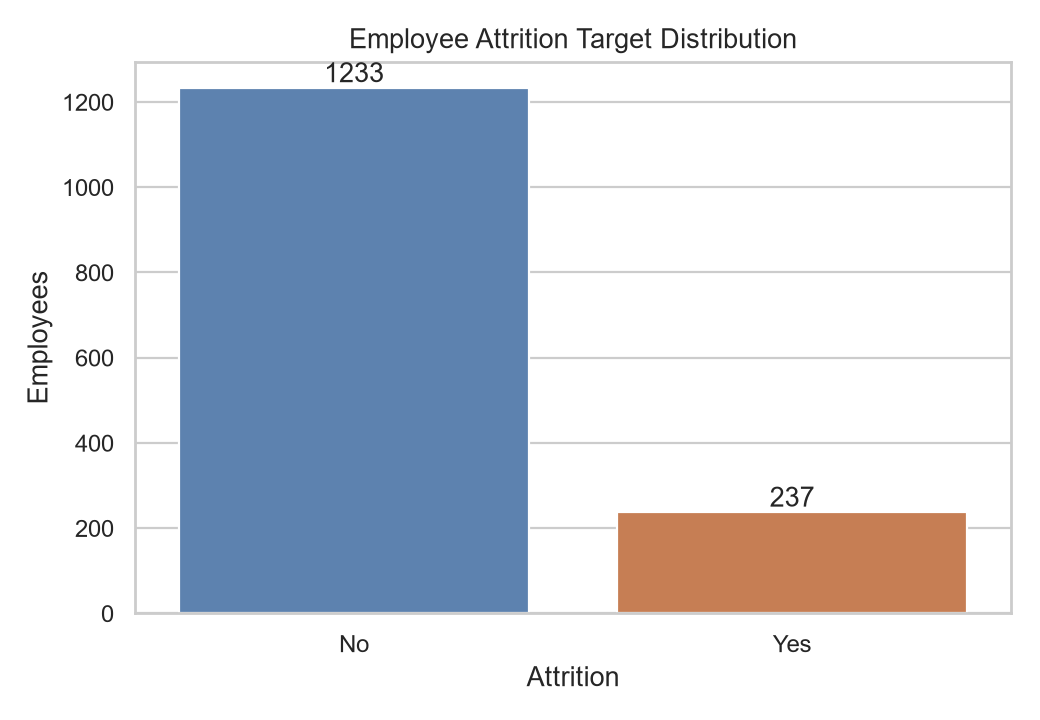

monthly_income_outliers.png


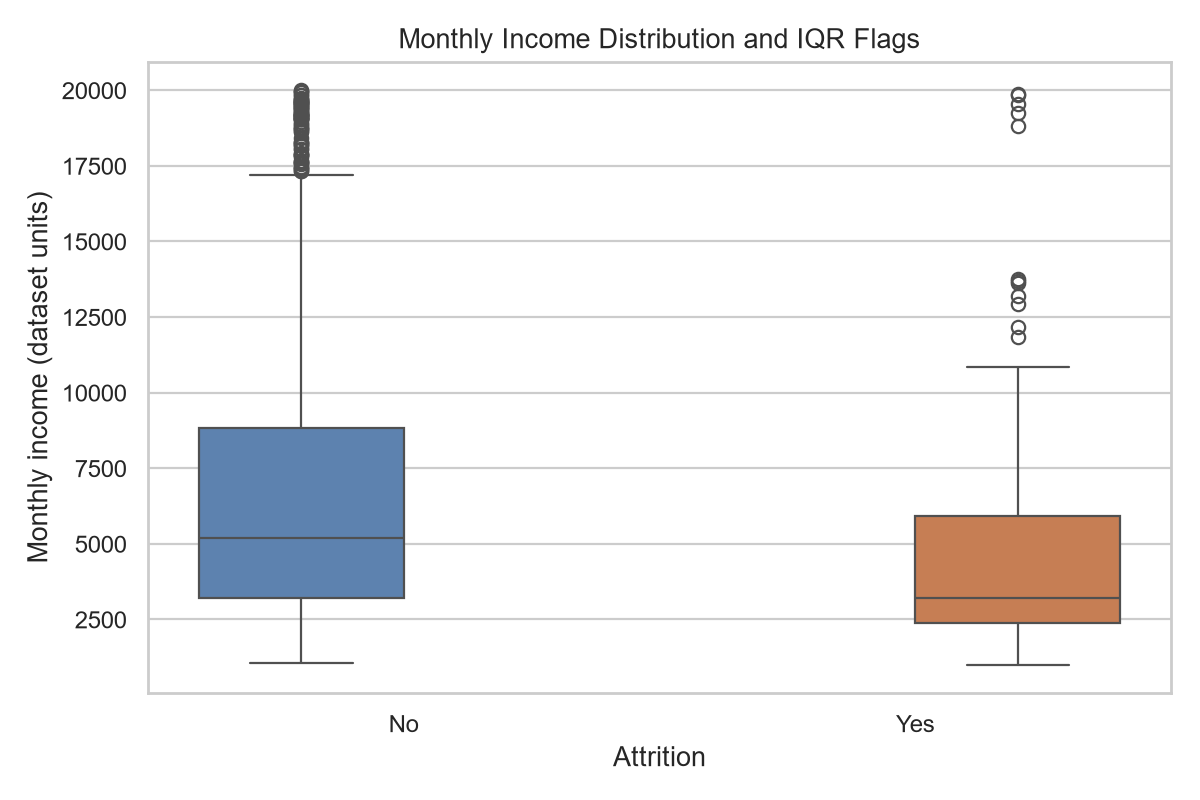

iqr_outlier_counts.png


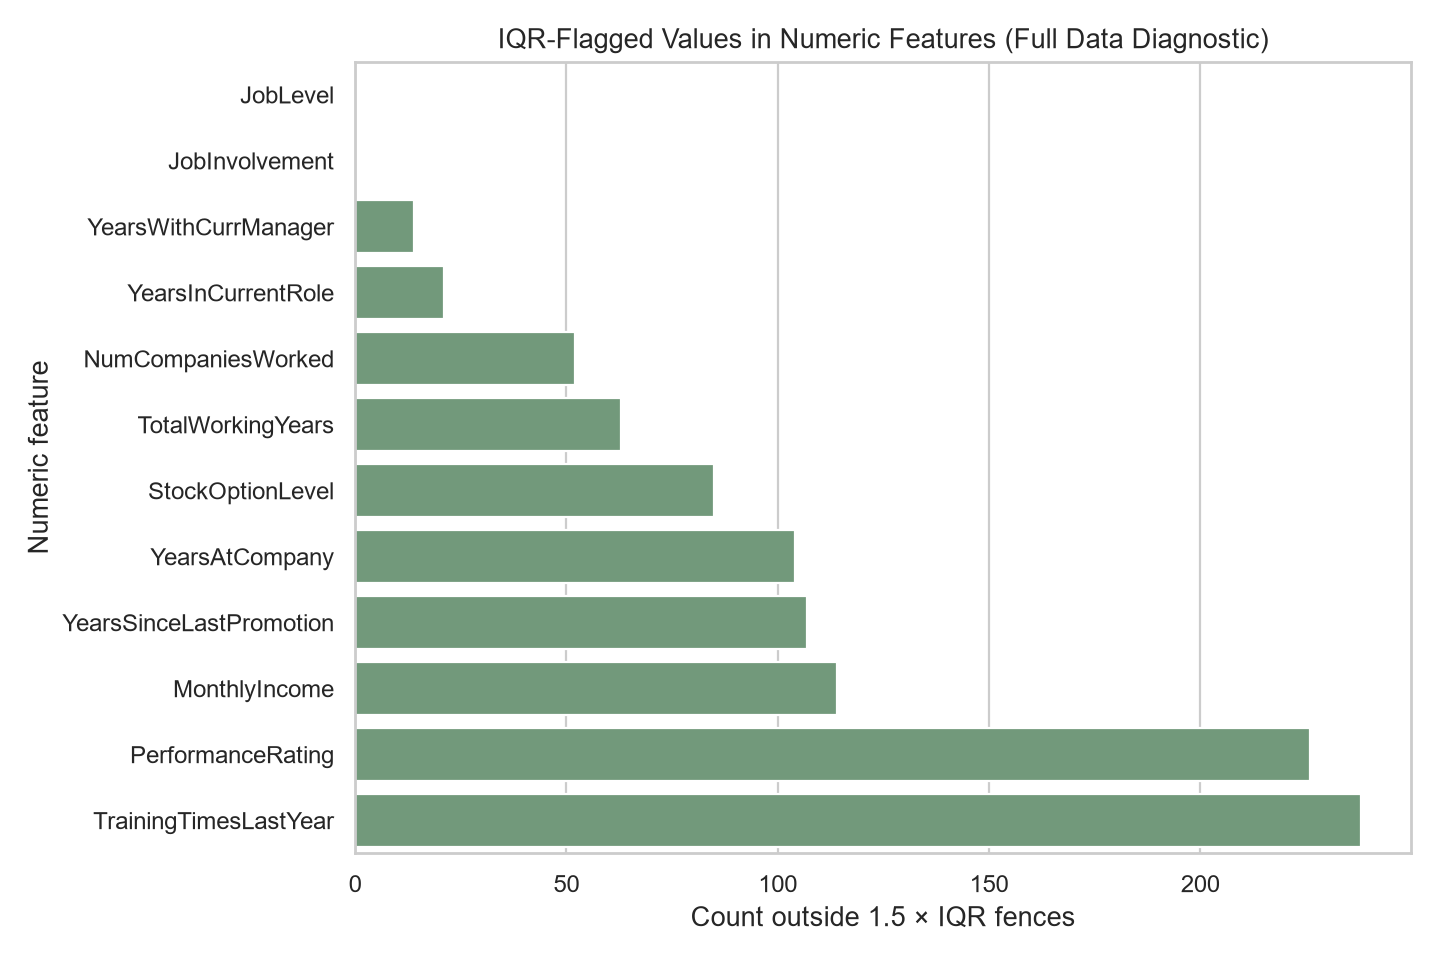

scaler_comparison_monthly_income.png


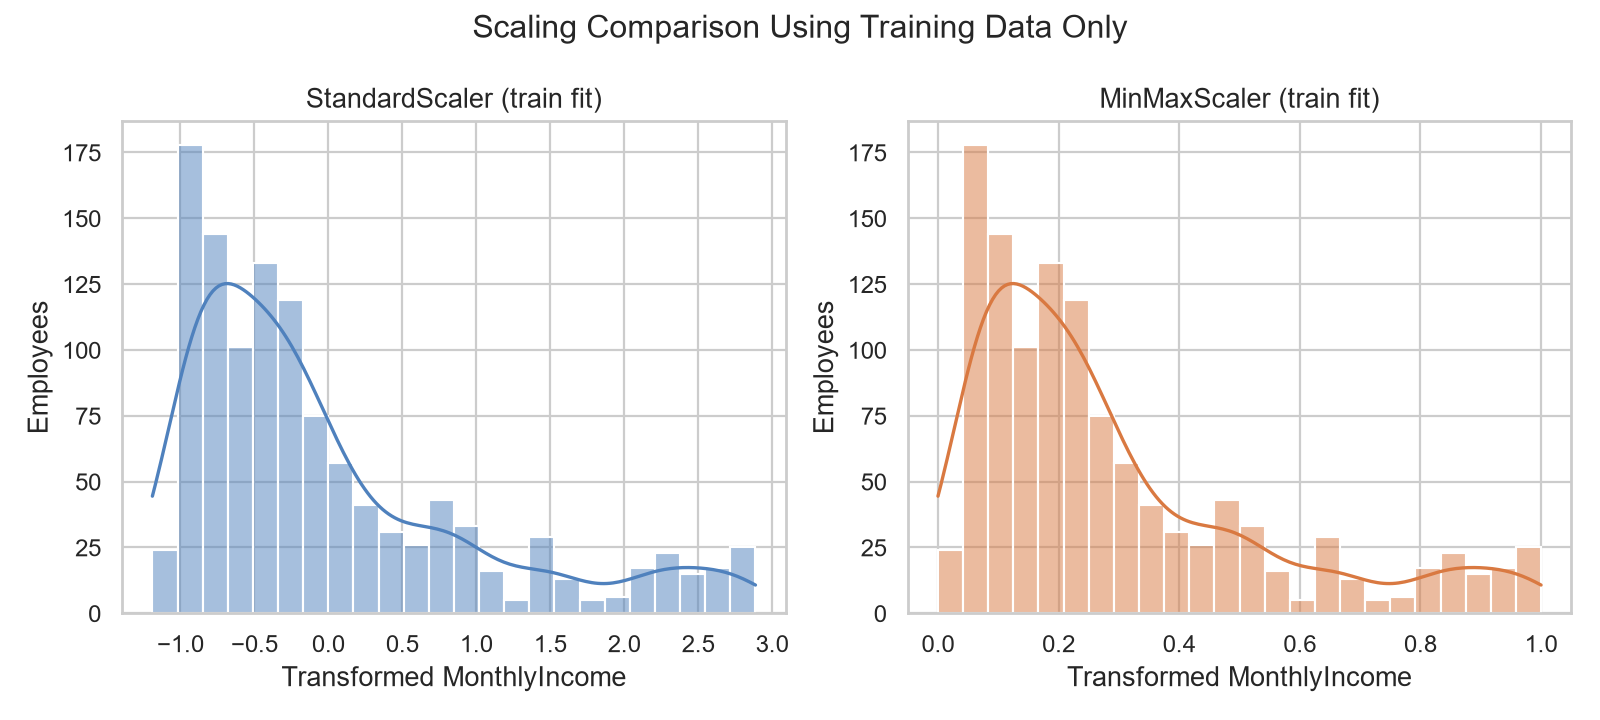

attrition_by_tenure_band.png


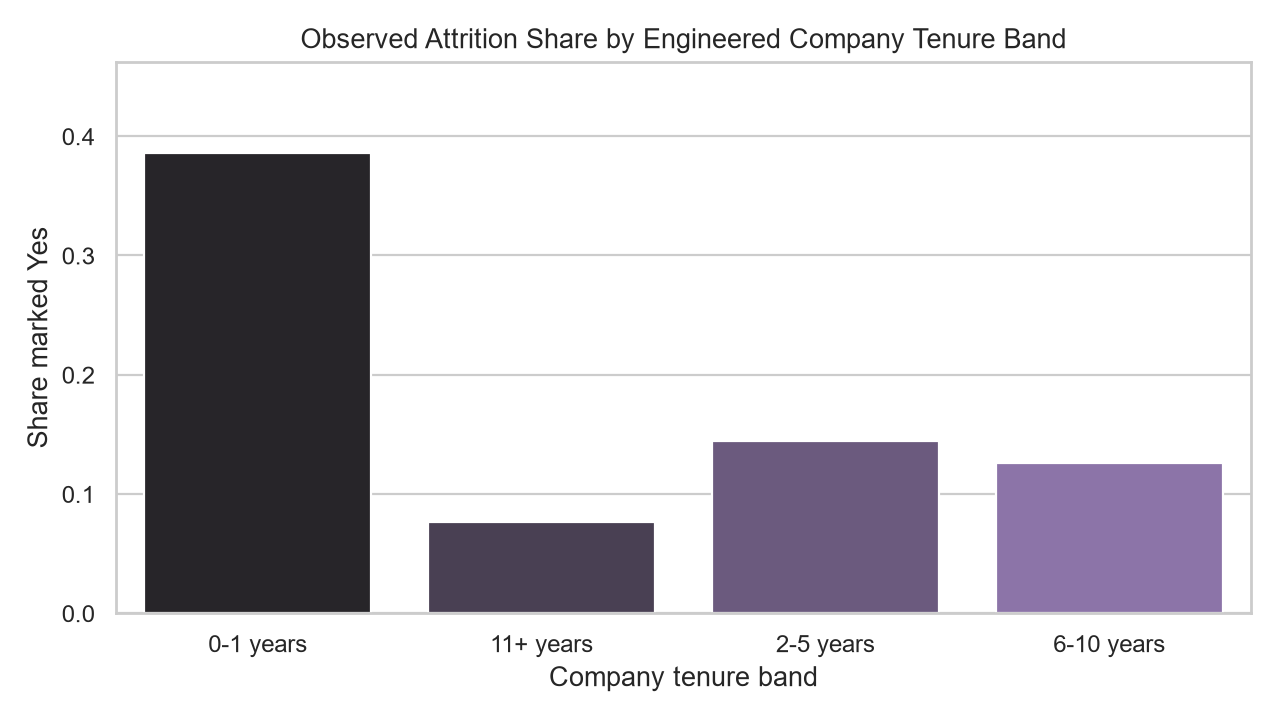

In [11]:
for filename in ['attrition_target_distribution.png', 'monthly_income_outliers.png', 'iqr_outlier_counts.png', 'scaler_comparison_monthly_income.png', 'attrition_by_tenure_band.png']:
    print(filename)
    display(Image(filename=str(PROJECT_ROOT / 'images' / filename)))

## Assumptions, limitations, and conclusion
This public IBM HR sample is fictional and static; patterns should not be interpreted as facts about a real workforce. IQR clipping is a modeling-preparation choice, not a claim that flagged employees are erroneous. The clean CSV retains real rows and target labels; imputation/encoding/scaling live in the train-fitted pipeline. This task does not train a classifier. In Task 3, refit this preprocessing pipeline within each cross-validation fold or model-selection pipeline to avoid validation leakage.